<a href="https://colab.research.google.com/github/ichaxpro/244107020023-Machine-Learning/blob/master/JS10/JS10_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1- Import Libraries

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

Step 2 - Load Dataset

In [ ]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    skipped = 0
    for folder in p.glob('*'):
        if not folder.is_dir():
            continue
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            if img is None:
                skipped += 1
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    print("File dilewati karena tidak bisa dibaca:", skipped)
    return img_list

train_dir = r"C:\Users\icha\OneDrive\Documents\Kuliah\Semester 5\244107020023-Machine-Learning\JS06\images\training"
test_dir  = r"C:\Users\icha\OneDrive\Documents\Kuliah\Semester 5\244107020023-Machine-Learning\JS06\images\test"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print("Jumlah training:", len(train_img))
print("Jumlah testing :", len(test_img))

File dilewati karena tidak bisa dibaca: 0
File dilewati karena tidak bisa dibaca: 0
Jumlah training: 240
Jumlah testing : 160


In [ ]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

Step 3 - Feature Extraction

In [ ]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

if len(X_train_img) == 0 or len(X_test_img) == 0:
    raise ValueError("Gambar training atau testing kosong. Jalankan ulang cell loading dengan path yang benar.")

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

print(X_train_feat.shape)
print(X_test_feat.shape)

(240, 34596)
(160, 34596)


Step 4 - Feature Standardization

In [ ]:
# Normalize features
if X_train_feat.ndim != 2 or X_test_feat.ndim != 2:
    raise ValueError("Ekstraksi HOG belum menghasilkan array 2D. Jalankan ulang Step 2 dan Step 3.")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

Step 5 - Create Training and Validation Data

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

# Convert labels to numpy arrays
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

Step 6 - Construct the ANN Model

In [ ]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

Step 7 - Train the Model

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 137ms/step - accuracy: 0.8073 - loss: 1.2487 - val_accuracy: 0.9375 - val_loss: 0.4438
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9583 - loss: 0.3378 - val_accuracy: 1.0000 - val_loss: 0.0092
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9948 - loss: 0.0228 - val_accuracy: 0.9792 - val_loss: 0.0835
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9896 - loss: 0.0601 - val_accuracy: 0.9792 - val_loss: 0.0535
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9948 - loss: 0.0108 - val_accuracy: 0.9792 - val_loss: 0.0704
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 0.0022 - val_accuracy: 0.9583 - val_loss: 0.1144
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.9375 - val_loss: 0.0867
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 1.0000 - loss: 1.5009e-08 - val_accuracy: 0.9583 - val_loss: 0.

Step 8 - Evaluate the Model with Test Data

In [ ]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Test Accuracy:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9312 - loss: 1.2158
Test Accuracy: 0.9312499761581421


Step 9 - Generate a Model Performance Report

In [ ]:
	y_pred_prob = model.predict(X_test_scaled)
	y_pred = (y_pred_prob > 0.5).astype(int)

	print(classification_report(y_test, y_pred))
	print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
              precision    recall  f1-score   support

           0       0.94      0.93      0.93        80
           1       0.93      0.94      0.93        80

    accuracy                           0.93       160
   macro avg       0.93      0.93      0.93       160
weighted avg       0.93      0.93      0.93       160

[[74  6]
 [ 5 75]]


Step 10 - Visualize the Training Process

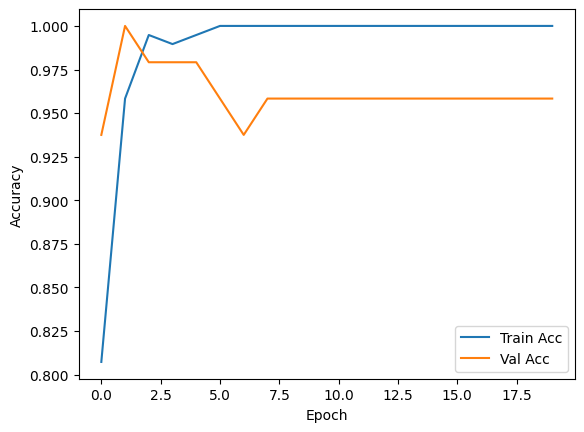

In [ ]:
	plt.plot(history.history['accuracy'], label='Train Acc')
	plt.plot(history.history['val_accuracy'], label='Val Acc')
	plt.xlabel('Epoch')
	plt.ylabel('Accuracy')
	plt.legend()
	plt.show()